# 01: Exploratory Data Analysis

**The question this project answers:** in Formula 1, how much of a result comes down to the driver,
and how much to the car they're given?

This is hard to answer because the two are almost never separable. A fast driver in a fast
car wins; a fast driver in a slow car finishes eighth. You never see a driver's skill on its own, only
skill combined with a car. This notebook prepares the data needed to separate them: where the data
comes from, which laps can be trusted, and what to measure.

### How F1 qualifying works

The rest of this notebook depends on the following:

- Each race weekend has a **qualifying session** that sets the starting order. Fastest lap wins
  **pole position** (first on the grid).
- Qualifying runs in three knockout segments: **Q1**, then **Q2**, then **Q3**. All 20 drivers run
  Q1; the slowest 5 are eliminated. The remaining 15 run Q2; 5 more are eliminated. The final 10
  contest Q3 for pole.
- Each team (called a **constructor**) enters exactly **two drivers in identical cars**. This is the
  single most useful fact in the dataset: comparing teammates holds the car constant.
- Drivers don't run flat out continuously. They do an **out-lap** (leaving the pits, building tyre
  temperature), then a fast **push lap**, then a slow **cooldown lap**. Only push laps reflect pace.
- Lap times can be **deleted** by officials, usually for exceeding track limits. A deleted lap
  doesn't count, even if it was fastest.

**Contents:**
1. The data.
2. First look at a qualifying session.
3. Deciding which laps count.
4. Why the qualifying segments aren't comparable.
5. Scaling to all eight seasons.
6. Data quality audit.
7. Choosing the target metric.
8. Outliers and the 107% rule.
9. Saving the dataset.
10. Quantified takeaways.

## Setup

In [11]:
import pandas as pd
import numpy as np
import requests
from urllib.parse import quote
from scipy import stats
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

## The data

Formula 1 timing data is published per session, but the official live-timing endpoint isn't usable
from a hosted notebook. I use the [TracingInsights](https://github.com/TracingInsights) mirror
instead, one public repository per season (2018–2025, Apache 2.0), serving the same underlying
timing data as JSON.

Per session it provides `session_laptimes.json` (lap-level timing, 43 fields), `weather.json`,
`rcm.json` (race control messages) and `drivers.json`.

Two checks before relying on it: the schema is identical across all eight seasons, and a spot-check
against a direct FastF1 fetch returns matching lap counts and times. It's still a third-party mirror
rather than an official source, which is a limitation worth naming in the write-up.

## First look at a qualifying session

One session (Miami 2023) with every column kept. I don't yet know which fields matter, so I don't
filter any out.

In [12]:
def load_session_json(year, grand_prix, session, filename):
    url = (f'https://raw.githubusercontent.com/TracingInsights/{year}/main/'
           f'{quote(grand_prix)}/{quote(session)}/{filename}')
    return requests.get(url, timeout=30).json()


miami_laps = pd.DataFrame(
    load_session_json(2023, 'Miami Grand Prix', 'Qualifying', 'session_laptimes.json')
)
print('shape:', miami_laps.shape)
print('columns:', miami_laps.columns.tolist())

shape: (304, 43)
columns: ['time', 'lap', 'compound', 'stint', 's1', 's2', 's3', 'ms1', 'ms2', 'ms3', 'life', 'pos', 'status', 'pb', 'sesT', 'drv', 'dNum', 'pout', 'pin', 's1T', 's2T', 's3T', 'vi1', 'vi2', 'vfl', 'vst', 'fresh', 'team', 'lST', 'lSD', 'del', 'delR', 'ff1G', 'iacc', 'wT', 'wAT', 'wH', 'wP', 'wR', 'wTT', 'wWD', 'wWS', 'qs']


In [13]:
miami_laps.head(15)

,time,lap,compound,stint,s1,s2,s3,ms1,ms2,ms3,life,pos,status,pb,sesT,drv,dNum,pout,pin,s1T,s2T,s3T,vi1,vi2,vfl,vst,fresh,team,lST,lSD,del,delR,ff1G,iacc,wT,wAT,wH,wP,wR,wTT,wWD,wWS,qs
0,None,1,SOFT,1,None,41.601,28.32,555331111,111111111,1333333,1,None,1,False,1009.238,ALB,23,902.497,None,None,980.918,1009.261,196.0,155.0,279.0,294.0,True,Williams,902.497,2023-05-06T20:00:03.483000000,False,None,False,False,995.480,29.3,58.0,1017.5,False,46.4,138,2.7,Q1
1,90.967,2,SOFT,1,31.047,34.427,25.493,111111111,113111111,133331,2,None,1,True,1100.205,ALB,23,None,None,1040.285,1074.712,1100.205,216.0,184.0,283.0,338.0,True,Williams,1009.238,2023-05-06T20:01:50.224000000,False,None,False,True,1115.478,29.2,57.0,1017.4,False,46.6,167,3.9,Q1
2,136.85,3,SOFT,1,52.26,49.517,35.073,000000000,000000000,0000000,3,None,1,False,1237.055,ALB,23,None,None,1152.465,1201.982,1237.055,155.0,128.0,280.0,256.0,True,Williams,1100.205,2023-05-06T20:03:21.191000000,False,None,False,True,1235.522,29.1,58.0,1017.4,False,45.8,140,3.0,Q1
3,89.326,4,SOFT,1,30.249,33.842,25.235,101111311,111111111,131011,4,None,1,True,1326.381,ALB,23,None,None,1267.304,1301.146,1326.381,221.0,191.0,281.0,338.0,True,Williams,1237.055,2023-05-06T20:05:38.041000000,False,None,False,True,1355.520,29.0,58.0,1017.5,False,45.4,95,3.2,Q1
4,None,5,SOFT,1,37.888,40.576,72.547,000000000,000000000,0000005,5,None,1,False,1477.393,ALB,23,None,1433.972,1364.333,1404.863,1477.565,183.0,162.0,None,270.0,True,Williams,1326.381,2023-05-06T20:07:07.367000000,False,None,False,False,1535.564,28.8,60.0,1017.4,False,43.6,102,4.1,Q1
5,147.728,6,SOFT,2,75.4,43.395,28.933,555000000,000000000,0000000,1,None,1,False,1625.121,ALB,23,1514.752,None,1552.793,1596.188,1625.121,209.0,139.0,282.0,291.0,True,Williams,1477.393,2023-05-06T20:09:38.379000000,False,None,False,False,1595.563,28.6,60.0,1017.5,False,42.7,148,2.5,Q1
6,88.234,7,SOFT,2,29.568,33.497,25.169,111111111,310001130,0001110,2,None,1,True,1713.355,ALB,23,None,None,1654.689,1688.186,1713.355,225.0,189.0,278.0,332.0,True,Williams,1625.121,2023-05-06T20:12:06.107000000,False,None,False,True,1715.592,28.7,59.0,1017.4,False,42.5,136,3.9,Q1
7,145.468,8,SOFT,2,53.73,55.955,35.783,000000000,000000000,0000000,3,None,1,False,1858.823,ALB,23,None,None,1767.085,1823.04,1858.823,143.0,119.0,283.0,174.0,True,Williams,1713.355,2023-05-06T20:13:34.341000000,False,None,False,True,2015.587,28.6,62.0,1017.2,False,43.8,116,1.5,Q1
8,114.838,9,SOFT,2,30.5,51.191,33.147,111110000,000000000,0000005,4,None,1,False,1973.661,ALB,23,None,1967.931,1889.323,1940.514,1973.661,217.0,166.0,None,317.0,True,Williams,1858.823,2023-05-06T20:15:59.809000000,False,None,False,False,2135.585,29.0,58.0,1017.2,False,46.1,146,3.5,Q1
9,None,10,SOFT,3,None,41.642,31.683,555111111,111111111,1111113,1,None,1,False,2801.368,ALB,23,2694.668,None,None,2769.714,2801.557,209.0,111.0,285.0,186.0,True,Williams,1973.661,2023-05-06T20:17:54.647000000,False,None,False,False,2555.593,28.5,60.0,1017.4,False,44.2,141,5.3,Q2


### What we have

304 laps × 43 fields for a single qualifying session. The fields that turn out to matter:

- **`time`**: lap time in seconds, with `'None'` strings for laps that weren't completed.
- **`qs`**: which segment the lap belongs to (`Q1`, `Q2`, `Q3`).
- **`iacc`**: an accuracy flag. Worth investigating; it may be the thing that separates genuine push
  laps from out-laps and cooldown laps.
- **`del`** / **`delR`**: whether the lap was deleted, and why. Track-limits deletions are common,
  and a deleted lap that happens to be someone's fastest would silently corrupt their pace estimate.
- **`compound`**, **`fresh`**, **`life`**: tyre type, whether the set was new, and how many laps
  were on it. All plausible pace confounds.
- **`wR`**: rainfall, recorded *per lap* rather than per session.

The per-lap rainfall and the deleted-lap flag are both better than what I'd planned to work with.

## Deciding which laps count

A driver's pace for a session is the fastest lap they set, but only counting laps that were real
attempts. Slow out-laps and cooldown laps exclude themselves by being slow, so the filter that matters is the
deleted-lap flag, because a deleted lap could be the fastest one.

In [14]:
miami_laps['time'] = pd.to_numeric(miami_laps['time'], errors='coerce')

print('deleted laps:', miami_laps['del'].sum(), 'of', len(miami_laps))
print(miami_laps.loc[miami_laps['del'], ['drv', 'lap', 'time', 'qs', 'delR']])

deleted laps: 0 of 304
Empty DataFrame
Columns: [drv, lap, time, qs, delR]
Index: []


In [15]:
best_including_deleted = miami_laps.groupby('drv')['time'].min()
best_excluding_deleted = miami_laps[~miami_laps['del']].groupby('drv')['time'].min()

best_comparison = pd.DataFrame({
    'with_deleted': best_including_deleted,
    'clean': best_excluding_deleted,
})
best_comparison['differs'] = best_comparison['with_deleted'] != best_comparison['clean']
print('drivers affected:', best_comparison['differs'].sum())
best_comparison.sort_values('clean')

drivers affected: 0


,with_deleted,clean,differs
drv,,,
VER,86.814,86.814,False
PER,86.841,86.841,False
LEC,86.964,86.964,False
ALO,87.097,87.097,False
SAI,87.148,87.148,False
OCO,87.444,87.444,False
BOT,87.564,87.564,False
GAS,87.612,87.612,False
MAG,87.673,87.673,False


Zero deleted laps in this session, so the filter is untested rather than unnecessary. I'll revisit it
on the full dataset.

## Why the qualifying segments aren't comparable

There is an inconsistency in the classification. Verstappen's fastest lap of the session (86.814) beats Pérez's
pole time (86.841), but Verstappen classified P9.

In [16]:
miami_laps[miami_laps['drv'] == 'VER'][['lap', 'qs', 'time', 'pb', 'del', 'iacc']]

,lap,qs,time,pb,del,iacc
272,1,Q1,NaN,False,False,False
273,2,Q1,88.424,True,False,True
274,3,Q1,NaN,False,False,False
275,4,Q1,NaN,False,False,False
276,5,Q1,87.363,True,False,True
277,6,Q1,105.770,False,False,False
278,7,Q2,NaN,False,False,False
279,8,Q2,87.110,True,False,True
280,9,Q2,119.689,False,False,False
281,10,Q2,NaN,False,False,False


In [17]:
segment_best = miami_laps.groupby(['drv', 'qs'])['time'].min().unstack()
print(segment_best.median().round(3), '<- median best per segment')
print()
segment_best

qs
Q1    88.074
Q2    87.612
Q3    87.786
dtype: float64 <- median best per segment



qs,Q1,Q2,Q3
drv,,,
ALB,88.234,87.795,NaN
ALO,88.179,87.097,87.202
BOT,87.864,87.564,NaN
DEV,88.325,88.395,NaN
GAS,88.061,87.612,87.786
HAM,87.846,87.975,NaN
HUL,87.945,87.903,NaN
LEC,87.713,86.964,87.861
MAG,87.809,87.673,87.767


### What's happening

Verstappen's fast lap came in **Q2**, and he set no representative Q3 time, the session was
red-flagged after Leclerc crashed. Taking `min(time)` per segment returns 108.678 for his Q3, which
is an aborted lap, not a pace lap.

Look at the `iacc` column: his real push laps (2, 5, 8, 11) are all `iacc=True`, and every slow lap
is `iacc=False`. That's the flag I was looking for.

There's an external check available here rather than having to trust it. The official classification
records **no Q3 time at all** for Verstappen: the sport itself discards that 108.678 lap. If the
`iacc` filter works correctly, it should reach the same conclusion.

In [18]:
miami_valid_laps = miami_laps[miami_laps['iacc'] & ~miami_laps['del']]
segment_best_valid = miami_valid_laps.groupby(['drv', 'qs'])['time'].min().unstack()

print('VER row - Q3 should now be NaN, matching the official classification:')
print(segment_best_valid.loc['VER'])
print()
print('median best per segment:')
print(segment_best_valid.median().round(3))
print()
print('drivers setting a valid time per segment:')
print(segment_best_valid.notna().sum())

VER row - Q3 should now be NaN, matching the official classification:
qs
Q1    87.363
Q2    86.814
Q3       NaN
Name: VER, dtype: float64

median best per segment:
qs
Q1    88.074
Q2    87.612
Q3    87.776
dtype: float64

drivers setting a valid time per segment:
qs
Q1    20
Q2    15
Q3     8
dtype: int64


### The lap-validity rule

**`iacc == True & del == False`.** Applying it makes Verstappen's Q3 `NaN`, the same verdict as the
official classification, arrived at independently. That's a real check rather than a self-consistent
one.

The segment medians expose the deeper problem: **Q1 is ~0.46s slower than Q2**. The track rubbers in
across the session, so segments aren't like-for-like. And participation is **20 / 15 / 8**: only
eight drivers set a valid Q3 time.

This is a problem. A driver eliminated in Q1 only ever runs on the slowest track surface,
so "best lap of the session" penalises slower drivers twice: once for being slower, and again for
never getting a run on a faster track. This would inflate the spread the project is trying to measure.

The fix is to compare drivers **within a single segment**. The question is which one still has
enough coverage to be usable.

In [19]:
segment_best_with_team = segment_best_valid.join(
    miami_valid_laps.groupby('drv')['team'].first()
)
drivers_per_team = segment_best_with_team.groupby('team')[['Q1', 'Q2', 'Q3']].count()
print('drivers per team with a valid time, by segment:')
print(drivers_per_team)
print()
print('teams where both teammates set a time:')
print((drivers_per_team == 2).sum(), '<- out of 10 teams, per segment')

drivers per team with a valid time, by segment:
                 Q1  Q2  Q3
team                       
Alfa Romeo        2   2   0
AlphaTauri        2   1   0
Alpine            2   2   2
Aston Martin      2   1   1
Ferrari           2   2   2
Haas F1 Team      2   2   1
McLaren           2   0   0
Mercedes          2   2   1
Red Bull Racing   2   2   1
Williams          2   1   0

teams where both teammates set a time:
Q1    10
Q2     6
Q3     2
dtype: int64 <- out of 10 teams, per segment


### Q1 is the only complete segment

Both teammates set a valid time in **10 of 10 teams in Q1**, 6 in Q2, 2 in Q3.

Q1 is the only segment every driver runs, and this matters. Reaching Q2
and Q3 comes down to being fast, so if I measured pace using Q3 times, I'd only ever see the drivers
quick enough to get there. The missing data would not be random. It would be missing
because those drivers were slow, which makes any conclusion drawn from it circular.

Two objections I can't settle from one session, and which need the full dataset:

1. **Sandbagging.** Top teams do just enough to advance in Q1. If they're cruising, their Q1 gap may
   be noise rather than pace.
2. **Tyre state.** Teams often save fresh softs for Q3 and run used rubber in Q1. If teammates differ,
   the gap measures tyre strategy as much as driver skill.

## Scaling to all eight seasons

173 Grands Prix, 2018–2025. I keep every column, since it's only ~80MB in total, and selecting fields now would mean guessing which
confounds matter before checking.

In [20]:
def grand_prix_names(year):
    url = f'https://api.github.com/repos/TracingInsights/{year}/contents'
    return [entry['name'] for entry in requests.get(url, timeout=30).json()
            if entry['type'] == 'dir' and 'Grand Prix' in entry['name']]


session_frames = []
for year in range(2018, 2026):
    names = grand_prix_names(year)
    print(f'{year}: {len(names)} GPs', end=' ')
    for grand_prix in names:
        try:
            session_json = load_session_json(year, grand_prix, 'Qualifying',
                                             'session_laptimes.json')
        except Exception:
            print(f'[skip {grand_prix}]', end=' ')
            continue
        session_df = pd.DataFrame(session_json)
        session_df['season'] = year
        session_df['gp'] = grand_prix
        session_frames.append(session_df)
    print('done')

all_laps = pd.concat(session_frames, ignore_index=True)
all_laps['time'] = pd.to_numeric(all_laps['time'], errors='coerce')
print()
print('shape:', all_laps.shape)
print('sessions:', all_laps.groupby(['season', 'gp']).ngroups)
print('memory:', round(all_laps.memory_usage(deep=True).sum() / 1e6, 1), 'MB')

2018: 21 GPs done
2019: 21 GPs done
2020: 17 GPs done
2021: 22 GPs done
2022: 22 GPs done
2023: 22 GPs done
2024: 24 GPs done
2025: 24 GPs done

shape: (53690, 45)
sessions: 173
memory: 82.5 MB


53,690 laps across 173 sessions, no failed fetches. The per-season Grand Prix counts match the real
calendars (including 2020's shortened 17-race COVID season), which is a reasonable check that the mirror is complete.

## Data quality audit

Before using any of these flags, I check what they actually contain across all sessions rather than
assuming the single-session dtypes hold everywhere.

In [21]:
for flag_column in ['del', 'iacc', 'pb', 'fresh', 'qs', 'compound']:
    print(f'--- {flag_column} (dtype={all_laps[flag_column].dtype}) ---')
    print(all_laps[flag_column].value_counts(dropna=False).head(8))
    print()

--- del (dtype=object) ---
del
False    51233
NaN       1832
True       625
Name: count, dtype: int64

--- iacc (dtype=object) ---
iacc
False    30430
True     21428
NaN       1832
Name: count, dtype: int64

--- pb (dtype=object) ---
pb
False    36423
True     15429
NaN       1832
None         6
Name: count, dtype: int64

--- fresh (dtype=object) ---
fresh
True     44470
False     7388
NaN       1832
Name: count, dtype: int64

--- qs (dtype=object) ---
qs
Q1     24832
Q2     15122
Q3      9340
NaN     4396
Name: count, dtype: int64

--- compound (dtype=object) ---
compound
SOFT            40274
INTERMEDIATE     3552
MEDIUM           2334
ULTRASOFT        2156
WET              1761
HYPERSOFT        1583
SUPERSOFT        1478
HARD              370
Name: count, dtype: int64



### What stood out

- **625 deleted laps exist.** The single Miami session had none, so the filter looked redundant. It
  isn't, it matters across the full dataset.
- **7,388 laps were set on used tyres.** The tyre-state confound is real and common, not theoretical.
- **Wet running is a substantial chunk**: 3,552 intermediate and 1,761 wet-compound laps. Also worth
  noting: 2018-era compounds (`ULTRASOFT`, `HYPERSOFT`, `SUPERSOFT`) no longer exist, so compound
  names aren't comparable across seasons.
- **`del`, `iacc`, `pb` and `fresh` all have exactly 1,832 NaN.** Identical counts point to whole
  sessions missing those fields rather than scattered gaps.
- **4,396 laps carry no segment label at all.**

The last two need locating, because a filter that cannot be applied everywhere is not useful.

In [22]:
sessions_missing_flags = all_laps[all_laps['iacc'].isna()].groupby(['season', 'gp']).size()
print('sessions missing iacc/del/pb/fresh:', len(sessions_missing_flags))
print(sessions_missing_flags)
print()

sessions_missing_segments = all_laps[all_laps['qs'].isna()].groupby(['season', 'gp']).size()
print('sessions with unlabelled-segment laps:', len(sessions_missing_segments), 'of 173')
print(sessions_missing_segments.sort_values(ascending=False).head(10))

sessions missing iacc/del/pb/fresh: 6
season  gp                      
2019    Mexican Grand Prix          303
        Monaco Grand Prix           427
        Russian Grand Prix          277
        Singapore Grand Prix        278
        Spanish Grand Prix          277
        United States Grand Prix    270
dtype: int64

sessions with unlabelled-segment laps: 14 of 173
season  gp                      
2019    Monaco Grand Prix           427
2024    São Paulo Grand Prix        425
        Qatar Grand Prix            374
        Las Vegas Grand Prix        347
        Azerbaijan Grand Prix       311
2019    Mexican Grand Prix          303
2024    Mexico City Grand Prix      289
        United States Grand Prix    281
2019    Singapore Grand Prix        278
        Russian Grand Prix          277
dtype: int64


### Missing data is concentrated, not scattered

- **6 sessions, all in 2019** (Mexico, Monaco, Russia, Singapore, Spain, USA) are missing every flag
  *and* every segment label.
- **8 more**, mostly 2024, have the flags but no segment labels.

That's **14 of 173 sessions (8%)** unusable for segment-based comparison. I exclude them and record
it as a limitation. Segments could be reconstructed from gaps in lap start times, but that method is
fragile and not worth the risk for 8% of the data.

## Choosing the target metric

Now I can settle the two objections to the Q1 comparison. First: do teammates actually run comparable
tyres in Q1?

In [23]:
is_valid_lap = all_laps['iacc'].eq(True) & all_laps['del'].eq(False)
valid_q1_laps = all_laps[is_valid_lap & all_laps['qs'].eq('Q1')]

best_lap_index = valid_q1_laps.groupby(['season', 'gp', 'drv'])['time'].idxmin().dropna()
best_laps_with_tyres = valid_q1_laps.loc[
    best_lap_index, ['season', 'gp', 'team', 'drv', 'time', 'compound', 'fresh', 'life']
]

teammate_pairs = (
    best_laps_with_tyres
    .groupby(['season', 'gp', 'team'])
    .filter(lambda team_rows: len(team_rows) == 2)
)
print('teammate pairs with both Q1 times:', len(teammate_pairs) // 2)
print()

tyre_match = teammate_pairs.groupby(['season', 'gp', 'team']).agg(
    n_compounds=('compound', 'nunique'),
    n_freshness_states=('fresh', 'nunique'),
)
print('pairs on DIFFERENT compound:', (tyre_match['n_compounds'] > 1).sum())
print('pairs on DIFFERENT tyre freshness:', (tyre_match['n_freshness_states'] > 1).sum())
print('pairs matched on both:',
      ((tyre_match['n_compounds'] == 1) & (tyre_match['n_freshness_states'] == 1)).sum())

teammate pairs with both Q1 times: 1491

pairs on DIFFERENT compound: 18
pairs on DIFFERENT tyre freshness: 116
pairs matched on both: 1362


### Tyre state is a small problem, not a fatal one

**1,491 teammate pairs** with both drivers setting a valid Q1 time. Of those, **91% match on both
compound and freshness**, 116 pairs differ on freshness, 18 on compound.

The confound is real but small. Rather than silently discarding 9% of the pairs now, I keep them
all and make "drop tyre-mismatched pairs" one of the sensitivity variants later. This keeps the choice testable rather than fixed.

Second objection: is the Q1 gap actually measuring pace, or are the top teams cruising?

In [24]:
valid_segment_laps = all_laps[is_valid_lap & all_laps['qs'].isin(['Q1', 'Q2', 'Q3'])]
driver_segment_best = (
    valid_segment_laps.groupby(['season', 'gp', 'team', 'drv', 'qs'])['time']
    .min()
    .reset_index()
)


def teammate_gap_for_segment(segment):
    segment_rows = driver_segment_best[driver_segment_best['qs'] == segment]
    complete_pairs = segment_rows.groupby(['season', 'gp', 'team']).filter(
        lambda team_rows: len(team_rows) == 2
    )
    times_by_team = (
        complete_pairs.sort_values('drv')
        .groupby(['season', 'gp', 'team'])['time']
        .agg(list)
    )
    return times_by_team.apply(
        lambda times: (times[0] - times[1]) / times[1] * 100
    ).rename(segment)


teammate_gaps = pd.concat(
    [teammate_gap_for_segment(seg) for seg in ['Q1', 'Q2', 'Q3']], axis=1
)
print('pairs per segment:', teammate_gaps.notna().sum().to_dict())
print()
print('gap std dev per segment (%):')
print(teammate_gaps.std().round(3))
print()
print('correlation between segment gaps (same pair):')
print(teammate_gaps.corr().round(3))

pairs per segment: {'Q1': 1491, 'Q2': 949, 'Q3': 558}

gap std dev per segment (%):
Q1    1.879
Q2    3.345
Q3    2.440
dtype: float64

correlation between segment gaps (same pair):
       Q1     Q2     Q3
Q1  1.000  0.021  0.082
Q2  0.021  1.000  0.150
Q3  0.082  0.150  1.000


Both figures are a problem.

The gaps barely correlate across segments (0.02–0.15), meaning a pair's Q1 gap tells you almost
nothing about their Q2 gap in the same session, which shouldn't be true if it were measuring a stable
skill difference. And the Q1 standard deviation of 1.88% works out to about 1.7 seconds between
teammates on a 90-second lap. Real teammates are typically within a tenth or two of each other, so
this is roughly five times too large.

Something is contaminating the measure. Before concluding that the metric is broken, I look at
the distribution rather than the summary statistics.

In [25]:
q1_gaps = teammate_gaps['Q1'].dropna()
print(q1_gaps.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(3))
print()
print('|gap| > 2%:', (q1_gaps.abs() > 2).sum(), 'of', len(q1_gaps))
print()
print('most extreme pairs:')
print(q1_gaps.reindex(q1_gaps.abs().sort_values(ascending=False).index).head(12).round(2))

count    1491.000
mean        0.021
std         1.879
min       -36.521
1%         -1.762
5%         -0.872
25%        -0.324
50%        -0.003
75%         0.324
95%         0.998
99%         2.639
max        43.907
Name: Q1, dtype: float64

|gap| > 2%: 39 of 1491

most extreme pairs:
season  gp                        team             
2021    French Grand Prix         Aston Martin         43.91
        Abu Dhabi Grand Prix      AlphaTauri          -36.52
2023    Saudi Arabian Grand Prix  Williams            -29.97
        Azerbaijan Grand Prix     AlphaTauri           12.76
2018    Azerbaijan Grand Prix     Toro Rosso          -10.96
2020    Turkish Grand Prix        Williams              8.92
2024    British Grand Prix        Red Bull Racing       7.67
                                  Alpine                5.55
2020    Turkish Grand Prix        Alfa Romeo Racing     5.02
2021    Mexico City Grand Prix    Aston Martin          4.35
2023    Mexico City Grand Prix    McLaren           

### The core distribution is fine, the tails aren't

- **Median −0.003%**, so no systematic bias from how I ordered the pairs.
- **IQR ±0.324%**, which is precisely the realistic teammate qualifying gap.
- But the extremes run to **−36.5%** and **+43.9%**, and **39 pairs (2.6%)** exceed 2%.

The extremes are interpretable rather than random: **2020 Turkey appears three times** (a famously
wet, low-grip session), **2024 Silverstone twice** (mixed conditions), plus a handful of individual
compromised laps.

In changing conditions the fastest lap mostly reflects when a driver ran as the track dried. That
is timing, not pace. So the question is whether those outliers alone destroyed the correlation.

In [26]:
rain_fraction = all_laps.groupby(['season', 'gp'])['wR'].apply(lambda rain: rain.eq(True).mean())
print('sessions with any rain:', (rain_fraction > 0).sum(), 'of', len(rain_fraction))
print()

gaps_with_rain = teammate_gaps.join(rain_fraction.rename('rain_fraction'))
dry_gaps = gaps_with_rain[gaps_with_rain['rain_fraction'].eq(0)]
dry_trimmed = dry_gaps[(dry_gaps['Q1'].abs() < 2) & (dry_gaps['Q2'].abs() < 2)]

print('Spearman (robust, all pairs):')
print(teammate_gaps.corr(method='spearman').round(3))
print()
print(f'Pearson, dry sessions only, |gap| < 2% (n={len(dry_trimmed)}):')
print(dry_trimmed[['Q1', 'Q2', 'Q3']].corr().round(3))
print()
print('gap std, dry + trimmed:', round(dry_trimmed['Q1'].std(), 3), '%')

sessions with any rain: 30 of 173

Spearman (robust, all pairs):
       Q1     Q2     Q3
Q1  1.000  0.354  0.327
Q2  0.354  1.000  0.406
Q3  0.327  0.406  1.000

Pearson, dry sessions only, |gap| < 2% (n=752):
       Q1     Q2     Q3
Q1  1.000  0.387  0.024
Q2  0.387  1.000  0.160
Q3  0.024  0.160  1.000

gap std, dry + trimmed: 0.39 %


### The outliers were the whole story

| | before | after cleaning |
|---|---|---|
| Q1 gap std dev | 1.879% | **0.390%** |
| Q1 ↔ Q2 correlation | 0.021 | **0.354** (Spearman) |

Once the outliers are handled, the standard deviation lands exactly where real teammate gaps sit, and
the correlation across segments turns clearly positive.

**What that means:** a single session's teammate gap carries real signal, but it's noisy. A
correlation of ~0.35 says roughly two-thirds of any individual measurement is session-specific
noise (traffic, a small mistake, a tow from another car) rather than a stable skill difference.

That's an argument for the modelling approach rather than a problem with the data. A hierarchical
model handles exactly this: instead of trusting each driver's raw average, it pulls estimates for
drivers with little data toward the overall average, and only lets drivers with many sessions move
far from it. A single bad weekend does not become the final word on a driver.

The heavy tails also suggest a Student-t likelihood may fit better than a normal one, which assumes
extreme values are rarer than they are here.

### Why the teammate gap can't be the target

The teammate gap is the cleanest *controlled* comparison available, same car, same session, same
segment. But this is also what rules it out as the thing to model.

**Both drivers share the car, so subtracting one from the other cancels the car out entirely.** If
Hamilton is 0.2% faster than his teammate, that tells me something about the two drivers and
*nothing* about whether the Mercedes was quick that year. A model built on gaps could rank drivers,
but it could never estimate car strength, half the question.

So the target is the **percentage gap to the session's fastest lap, computed within Q1 only**:

- **Q1 only** → same track state for everyone, no segment or selection confound.
- **All 20 drivers** → complete coverage, no elimination bias.
- **Session-relative** → a lap at Monaco takes ~70 seconds and one at Spa ~105, so raw times can't be
  compared. Measuring each driver as a percentage off the fastest lap *of that session* makes
  circuits comparable and cancels out the day's weather and track conditions.
- **Absolute, not differenced** → the car effect survives, identified by drivers who change teams
  between seasons.

The teammate analysis is not wasted. It showed the within-team signal is real and measured how
noisy it is. It informs the model rather than being the model.

In [27]:
driver_session = (
    valid_q1_laps.groupby(['season', 'gp', 'team', 'drv'])['time']
    .agg(best_lap='min', n_valid_laps='size')
    .reset_index()
)

session_fastest = driver_session.groupby(['season', 'gp'])['best_lap'].transform('min')
driver_session['gap_to_fastest'] = (
    (driver_session['best_lap'] - session_fastest) / session_fastest * 100
)
driver_session = driver_session.join(
    rain_fraction.rename('rain_fraction'), on=['season', 'gp']
)

print('rows:', len(driver_session))
print('sessions:', driver_session.groupby(['season', 'gp']).ngroups)
print('drivers:', driver_session['drv'].nunique(),
      '| constructors:', driver_session['team'].nunique())
print()
print(driver_session['gap_to_fastest'].describe(percentiles=[.05, .5, .95, .99]).round(3))
print()
print('skew:', round(stats.skew(driver_session['gap_to_fastest'].dropna()), 3))
print('wet-session rows:', (driver_session['rain_fraction'] > 0).sum())

rows: 3029
sessions: 156
drivers: 43 | constructors: 19

count    3029.000
mean        1.193
std         1.905
min         0.000
5%          0.000
50%         0.961
95%         2.783
99%         4.909
max        58.758
Name: gap_to_fastest, dtype: float64

skew: 18.349
wet-session rows: 532


### A skew problem

3,029 driver-sessions across 156 usable sessions, 43 drivers, 19 constructors, but the target has a
**skew of 18.3** and a maximum of 58.8%.

My first hypothesis: measuring against the session's *fastest* driver forces one driver per session to
exactly zero and everyone else positive, so the distribution is floored at zero. A Gaussian would put
probability mass on impossible negative values.

If that's the cause, measuring against the session *median* instead should fix it: half the field
lands above, half below, so there's no floor. Changing the reference point shifts every driver in a
session by the same amount, so the differences between drivers, the thing I actually care about, 
survive unchanged.

In [28]:
session_median = driver_session.groupby(['season', 'gp'])['best_lap'].transform('median')
driver_session['gap_to_median'] = (
    (driver_session['best_lap'] - session_median) / session_median * 100
)
driver_session['log_gap_to_fastest'] = np.log1p(driver_session['gap_to_fastest'])

dry_sessions = driver_session[driver_session['rain_fraction'].eq(0)]

for metric in ['gap_to_fastest', 'gap_to_median', 'log_gap_to_fastest']:
    print(f'{metric:20s} all: skew={stats.skew(driver_session[metric]):7.2f}  '
          f'std={driver_session[metric].std():6.3f}   '
          f'dry: skew={stats.skew(dry_sessions[metric]):7.2f}  '
          f'std={dry_sessions[metric].std():6.3f}')

gap_to_fastest       all: skew=  18.35  std= 1.905   dry: skew=  22.46  std= 1.872
gap_to_median        all: skew=  21.87  std= 1.746   dry: skew=  23.45  std= 1.811
log_gap_to_fastest   all: skew=   1.14  std= 0.400   dry: skew=   1.10  std= 0.362


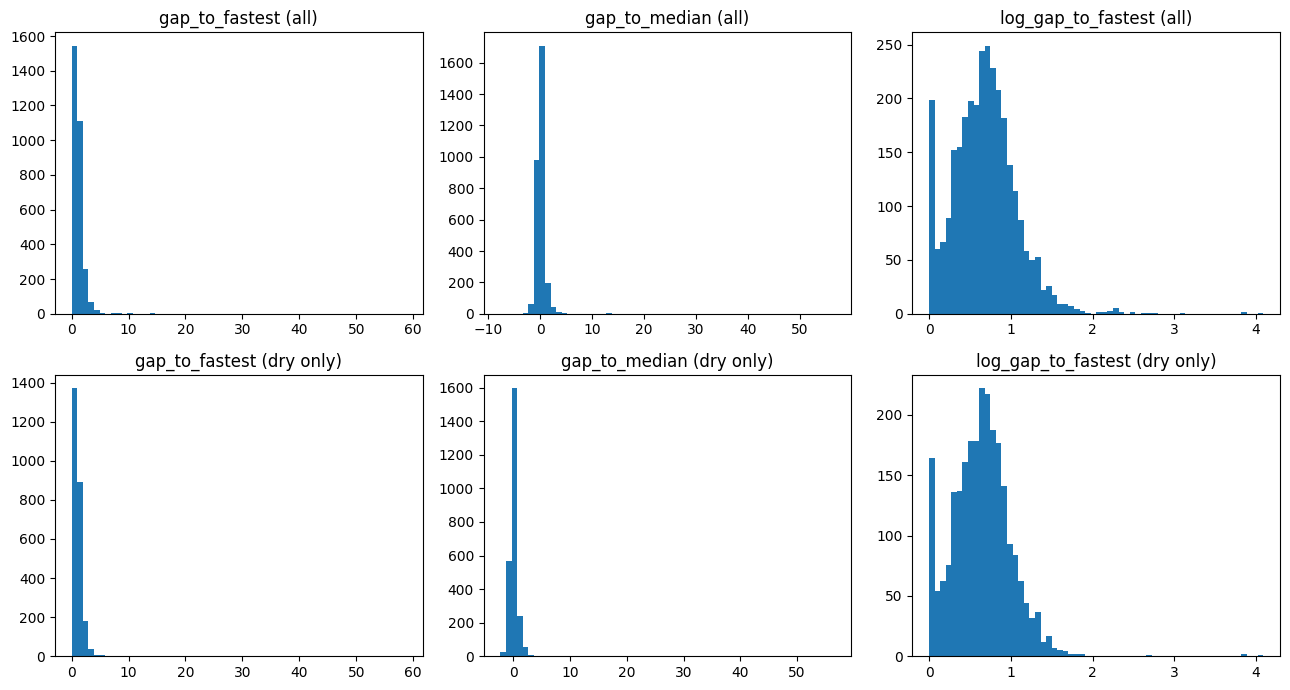

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for column, metric in enumerate(['gap_to_fastest', 'gap_to_median', 'log_gap_to_fastest']):
    axes[0, column].hist(driver_session[metric], bins=60)
    axes[0, column].set_title(f'{metric} (all)')
    axes[1, column].hist(dry_sessions[metric], bins=60)
    axes[1, column].set_title(f'{metric} (dry only)')
plt.tight_layout()
plt.show()

### The hypothesis was wrong

Median-referencing made skew **worse** (21.9 vs 18.4), and dry-only sessions are worse than all
sessions (22.5 vs 18.4).

So it's neither the zero floor nor wet running. It's extreme right-tail outliers in *dry* sessions
that the `iacc` flag isn't catching. A log transform reduces the skew to 1.14, but reaching for a
transform before understanding what those laps are would conceal the problem rather than solve it.

In [30]:
worst_gaps = driver_session.nlargest(15, 'gap_to_fastest')
print(worst_gaps[['season', 'gp', 'team', 'drv', 'best_lap', 'gap_to_fastest',
                  'n_valid_laps', 'rain_fraction']].round(2).to_string(index=False))
print()
for threshold in [10, 5, 3]:
    print(f'gap > {threshold}%:', (driver_session['gap_to_fastest'] > threshold).sum(),
          f'of {len(driver_session)}')

 season                       gp            team drv  best_lap  gap_to_fastest  n_valid_laps  rain_fraction
   2021     Abu Dhabi Grand Prix      AlphaTauri TSU    131.52           58.76             2           0.00
   2021        French Grand Prix    Aston Martin STR    132.58           45.70             1           0.00
   2023 Saudi Arabian Grand Prix        Williams SAR    128.51           44.78             1           0.00
   2020       Turkish Grand Prix        Williams LAT    141.61           20.54             1           0.12
   2018    Azerbaijan Grand Prix      Toro Rosso HAR    117.35           14.45             1           0.18
   2023    Azerbaijan Grand Prix      AlphaTauri DEV    115.28           13.84             1           0.00
   2020       Turkish Grand Prix    Haas F1 Team GRO    132.91           13.13             2           0.12
   2024       British Grand Prix          Alpine GAS     99.80           11.45             3           0.09
   2020       Turkish Grand 

In [31]:
is_outlier = driver_session['gap_to_fastest'] > 5
print('valid-lap count vs gap size:')
print(driver_session.groupby(is_outlier)['n_valid_laps']
      .describe()[['count', 'mean', 'min', '50%']].round(2))

valid-lap count vs gap size:
                 count  mean  min  50%
gap_to_fastest                        
False           3000.0  3.53  1.0  3.0
True              29.0  2.52  1.0  2.0


### Two distinct causes

1. **Disrupted sessions.** The three worst cases (+58.8%, +45.7%, +44.8%) each had only **1–2 valid
   laps** and no rain. A dry lap 45%+ off pole isn't slow pace: it's a wrecked lap that `iacc` still
   marked as accurate. Outliers average 2.5 valid laps against 3.5 for everyone else.
2. **Genuinely wet sessions.** 2020 Turkey supplies 8 of the top 15 and 2024 Silverstone 2 more. Those
   gaps are *real* (the field genuinely spread out) so they're a modelling question, not a
   data-cleaning one.

## Outliers and the 107% rule

I need a rule for "this lap doesn't represent the driver's pace", and F1 already has one.

**The 107% rule:** a driver who fails to lap within 107% of the fastest Q1 time doesn't qualify for
the race. The sport itself treats that as the boundary of a legitimate competitive lap, it applies to
exactly the segment I'm using, and it's defensible in a way that "I dropped the top 1%" isn't. I
didn't pick a threshold to make the histogram behave; I borrowed the one the sport already enforces.

In [32]:
within_107 = driver_session['gap_to_fastest'] <= 7
print('excluded by 107% rule:', (~within_107).sum(), 'of', len(driver_session))
print()
print('excluded rows, by rain:')
excluded = driver_session[~within_107]
print('  wet sessions (rain > 0):', (excluded['rain_fraction'] > 0).sum())
print('  dry sessions:', (excluded['rain_fraction'] == 0).sum())
print()
print('median valid laps - excluded:', excluded['n_valid_laps'].median(),
      '| kept:', driver_session[within_107]['n_valid_laps'].median())

excluded by 107% rule: 21 of 3029

excluded rows, by rain:
  wet sessions (rain > 0): 17
  dry sessions: 4

median valid laps - excluded: 2.0 | kept: 3.0


In [33]:
qualified = driver_session[within_107]
qualified_dry = qualified[qualified['rain_fraction'].eq(0)]

for label, frame in [('all sessions', qualified), ('dry only', qualified_dry)]:
    gap = frame['gap_to_fastest']
    print(f'{label:14s} n={len(frame):5d}  skew={stats.skew(gap):6.2f}  '
          f'std={gap.std():5.3f}  median={gap.median():5.3f}  max={gap.max():6.3f}')

all sessions   n= 3008  skew=  1.63  std=0.828  median=0.954  max= 6.906
dry only       n= 2493  skew=  1.43  std=0.734  median=0.902  max= 5.611


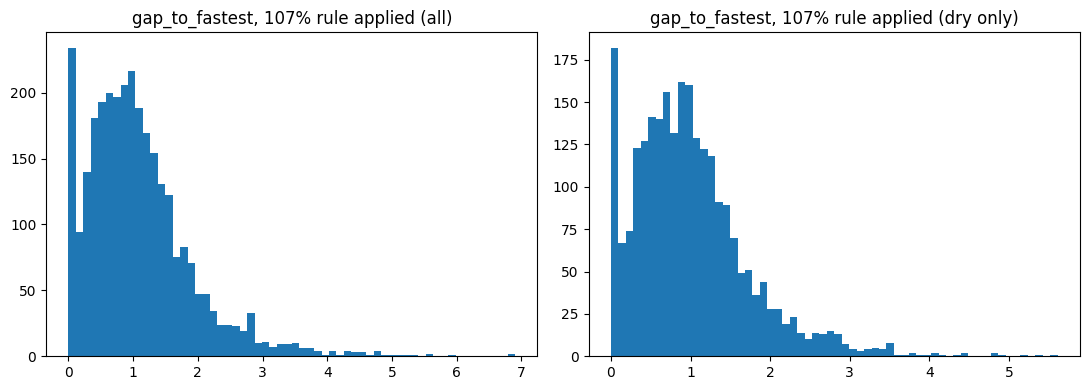

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(qualified['gap_to_fastest'], bins=60)
axes[0].set_title('gap_to_fastest, 107% rule applied (all)')
axes[1].hist(qualified_dry['gap_to_fastest'], bins=60)
axes[1].set_title('gap_to_fastest, 107% rule applied (dry only)')
plt.tight_layout()
plt.show()

### What the rule does

| | before | after 107% rule |
|---|---|---|
| skew | 18.35 | **1.63** (dry: 1.43) |
| std dev | 1.905% | **0.828%** (dry: 0.734%) |
| maximum | 58.8% | 6.9% |
| rows removed |, | **21 of 3,029 (0.7%)** |

Skew drops by an order of magnitude while discarding under 1% of the data, and it removes the right
rows: 17 wet, 4 dry, with a median of 2 valid laps against 3 for those kept.

A residual skew of 1.63 is workable. The likelihood itself gets decided formally in the modelling
notebook via `az.compare()` (LOO/WAIC), here I just record what the candidate transforms look like so
that comparison starts from evidence.

In [35]:
qualified = qualified.copy()
qualified['log_gap'] = np.log1p(qualified['gap_to_fastest'])
qualified['sqrt_gap'] = np.sqrt(qualified['gap_to_fastest'])

for metric in ['gap_to_fastest', 'log_gap', 'sqrt_gap']:
    values = qualified[metric]
    print(f'{metric:16s} skew={stats.skew(values):6.2f}  std={values.std():6.3f}  '
          f'min={values.min():6.3f}  max={values.max():6.3f}')

gap_to_fastest   skew=  1.63  std= 0.828  min= 0.000  max= 6.906
log_gap          skew=  0.26  std= 0.364  min= 0.000  max= 2.068
sqrt_gap         skew= -0.10  std= 0.416  min= 0.000  max= 2.628


`sqrt` is essentially symmetric (−0.10), `log1p` is mildly right-skewed (0.26), untransformed is 1.63.
All three are viable candidates for the model comparison.

## Saving the dataset

One row per driver per session. I keep **all** rows and carry the flags alongside, so the wet-session
and 107% variants stay runnable as sensitivity checks rather than being irreversibly baked in.

In [36]:
stage_a = driver_session.assign(within_107=within_107)[
    ['season', 'gp', 'team', 'drv', 'best_lap', 'n_valid_laps',
     'gap_to_fastest', 'rain_fraction', 'within_107']
]
stage_a.to_csv('/kaggle/working/q1_pace.csv', index=False)

print('saved q1_pace.csv:', stage_a.shape)
print('modelling rows (107% applied):', stage_a['within_107'].sum())
print('drivers:', stage_a['drv'].nunique(), '| constructors:', stage_a['team'].nunique(),
      '| seasons:', stage_a['season'].nunique())
print()
print('drivers per constructor count (identification for driver-vs-car separation):')
print(stage_a.groupby('drv')['team'].nunique().value_counts().sort_index())

saved q1_pace.csv: (3029, 9)
modelling rows (107% applied): 3008
drivers: 43 | constructors: 19 | seasons: 8

drivers per constructor count (identification for driver-vs-car separation):
team
1    20
2    11
3     6
4     3
5     3
Name: count, dtype: int64


## Quantified takeaways

1. **The lap-validity rule is `iacc == True & del == False`**, and it matches an independent reference: it independently reaches the same verdict as the official classification on
   Verstappen's aborted Miami 2023 Q3 lap. Without it, taking the minimum lap time picks up aborted
   and cooldown laps. **625 deleted laps** across the dataset make the deletion filter necessary,
   even though the first session I inspected had none.

2. **Qualifying segments aren't comparable, so the target is restricted to Q1.** The track gains
   ~0.46s between Q1 and Q2, and participation falls **20 → 15 → 8** because reaching each segment
   depends on being fast. Measuring across segments would penalise slower drivers twice, once for
   being slower, again for only ever running on the slowest track, inflating the very spread this
   project sets out to measure.

3. **The teammate gap validates the signal but can't be the target.** Across **1,491 teammate pairs**
   (91% matched on tyre compound and freshness), the cleaned gap has a standard deviation of 0.39%
   and a cross-segment correlation of 0.35. That is real signal, but it is noisy from session to
   session, which is the case for partial pooling. It's unusable as the target because both drivers share the
   car, so differencing cancels the car effect and leaves car strength unestimable.

4. **F1's own 107% rule handles the outliers better than any statistical cutoff.** The raw skew of
   18.3 came from dry laps 45–59% off pole that `iacc` still marked accurate, drivers with 1–2 valid
   laps whose sessions fell apart. Applying the sport's own qualifying threshold cuts skew to
   **1.63** while dropping **21 rows of 3,029 (0.7%)**.

5. **Driver-versus-car separation depends on how connected each driver is to the rest of the grid.**
   23 of 43 changed constructor during 2018–2025 (11 drove for two teams, 6 for three, 3 for four, 3
   for five), and those moves link constructors onto a common scale. Changing teams isn't the only
   route, though, sharing a car with a succession of different teammates does the same job. Notebook
   03 quantifies which matters: interval width correlates −0.90 with number of sessions and −0.77
   with number of distinct teammates, but only −0.56 with team changes. The drivers to treat
   cautiously are those with few sessions or few teammates, not single-team drivers as such.